In [96]:
import numpy as np
import control as ct
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.signal import cont2discrete

## Problem 1

### Problem 1.1

In [97]:
A = np.array([
    [-1, 1], 
    [1, -1]
])

B = np.array([
    [1],
    [0]
])

In [98]:
print("A shape:\n", A.shape)
print("B shape:\n", B.shape)

A shape:
 (2, 2)
B shape:
 (2, 1)


In [99]:
C = np.array([
    [1, 0]
])

D = np.array([[0]])

In [100]:
print("C shape:\n", C.shape)
print("D shape:\n", D.shape)

C shape:
 (1, 2)
D shape:
 (1, 1)


In [101]:
dt = 0.01

Ad, Bd, Cd, Dd, _ = cont2discrete((A, B, C, D), dt)

In [102]:
print("PROBLEM 1.1\n")

print(f"Sampling time dt = {dt}")
print("\nAd =\n", Ad)
print("\nBd =\n", Bd)
print("\nCd =\n", Cd)
print("\nDd =\n", Dd)

PROBLEM 1.1

Sampling time dt = 0.01

Ad =
 [[0.99009934 0.00990066]
 [0.00990066 0.99009934]]

Bd =
 [[9.95033167e-03]
 [4.96683267e-05]]

Cd =
 [[1 0]]

Dd =
 [[0]]


### Problem 1.2

In [103]:
Q_0 = np.array([[1, 0], [0, 1]])
Q_1 = np.array([[10, 0], [0, 1]])
Q_2 = np.array([[1, 0], [0, 20]])

Q_list = [Q_0, Q_1, Q_2]

R = np.array([[1]])

In [104]:
for i, Q in enumerate(Q_list):
    K_dlqr, _, _ = ct.dlqr(Ad, Bd, Q, R)
    K = -K_dlqr
    print(f"\nFor Q_{i} =\n{Q}\n")
    print(f"Optimal gain K_{i} =\n", K)


For Q_0 =
[[1 0]
 [0 1]]

Optimal gain K_0 =
 [[-0.79384952 -0.6147331 ]]

For Q_1 =
[[10  0]
 [ 0  1]]

Optimal gain K_1 =
 [[-2.50150904 -0.77322409]]

For Q_2 =
[[ 1  0]
 [ 0 20]]

Optimal gain K_2 =
 [[-1.75338413 -2.78895931]]


## Problem 2

### Problem 2.1

In [105]:
T = 20

x_initial = np.array([
    [-0.1, 0.1],
    [-0.1, 0.1]
])

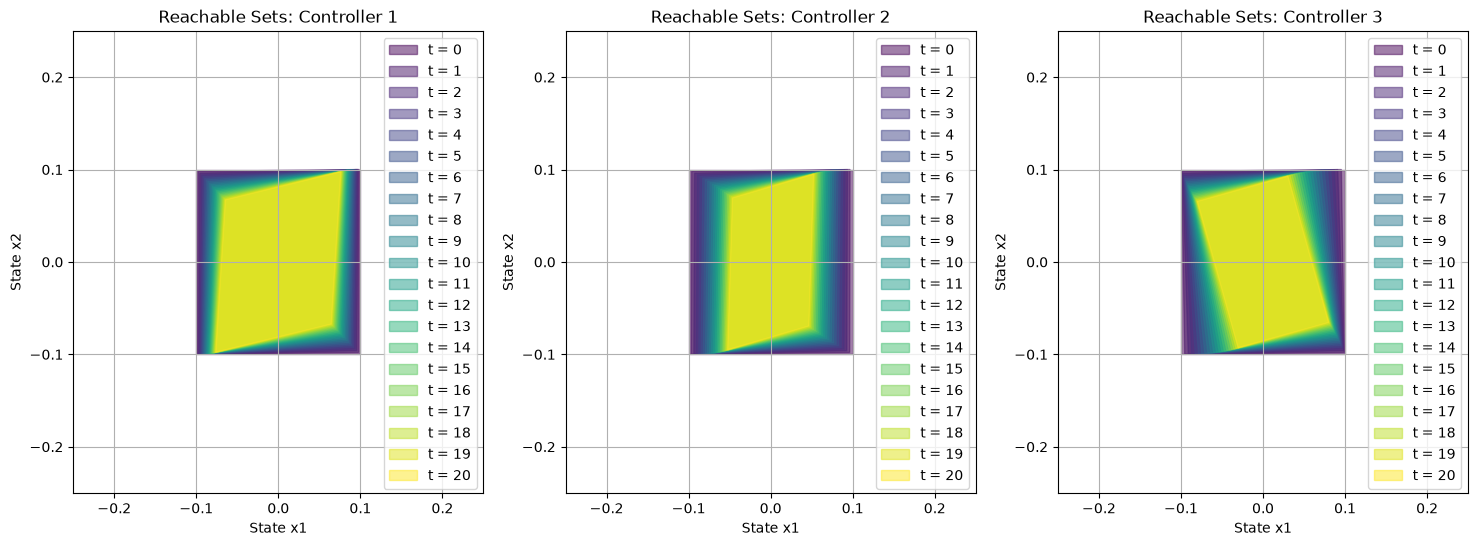

In [106]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

colors = plt.cm.viridis(np.linspace(0, 1, T + 1))

for i, Q in enumerate(Q_list):
    K_dlqr, _, _ = ct.dlqr(Ad, Bd, Q, R)
    K = -K_dlqr

    x_vertices = np.zeros((T + 1, 4, 2))

    x_vertices[0] = np.array([
        [x_initial[0, 0], x_initial[1, 0]],
        [x_initial[0, 1], x_initial[1, 0]],
        [x_initial[0, 1], x_initial[1, 1]],
        [x_initial[0, 0], x_initial[1, 1]]
    ])

    for t in range(1, T + 1):
        for v in range(4):
            x_vertices[t, v] = Ad @ x_vertices[t - 1, v] + Bd @ (K @ x_vertices[t - 1, v])

    ax = axes[i]

    for t in range(T + 1):
        polygon = patches.Polygon(
            x_vertices[t], 
            closed=True,
            color=colors[t], 
            alpha=0.5, 
            label=f't = {t}'
        )
        ax.add_patch(polygon)

    x_values = x_vertices[:, :, 0]
    y_values = x_vertices[:, :, 1]

    x_min, x_max = x_values.min(), x_values.max()
    y_min, y_max = y_values.min(), y_values.max()

    ax.set_xlim(x_min - 0.15, x_max + 0.15)
    ax.set_ylim(y_min - 0.15, y_max + 0.15)

    ax.set_title(f"Reachable Sets: Controller {i + 1}")
    ax.set_xlabel("State x1")
    ax.set_ylabel("State x2")
    ax.legend()
    ax.grid(True)


plt.show()

### Problem 2.2

Initial state x0 =
[[ 0.05479121]
 [-0.01222431]]

Controller 1: Cost J = 0.17241929
Controller 2: Cost J = 0.68932297
Controller 3: Cost J = 0.28707258


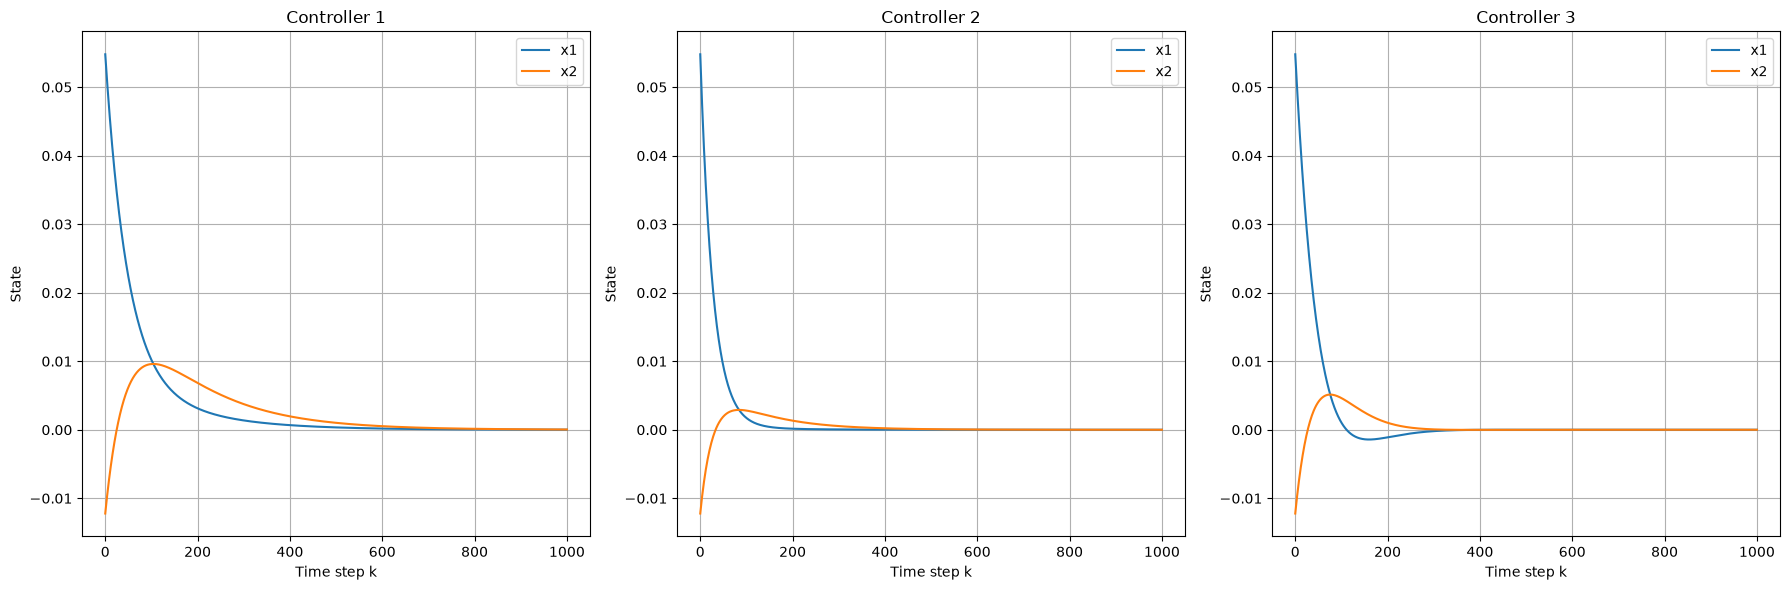

Controller costs: [0.17241928741558127, 0.6893229712393066, 0.28707258113748507]


In [107]:
trajectories = []
controller_costs = []

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

rng = np.random.default_rng(seed=42)
x0 = rng.uniform(x_initial[:, 0], x_initial[:, 1]).reshape(2, 1)

print(f"Initial state x0 =\n{x0}\n")

T = 1000

for i, Q in enumerate(Q_list):
    K_dlqr, _, _ = ct.dlqr(Ad, Bd, Q, R)

    K = -K_dlqr

    x_trajectory = np.zeros((T + 1, 2, 1))
    u_trajectory = np.zeros((T, 1, 1))



    x_trajectory[0] = x0
    J = 0

    for k in range(T):
        x_k = x_trajectory[k]
        u_k = K @ x_k

        u_trajectory[k] = u_k

        x_trajectory[k + 1] = Ad @ x_k + Bd @ u_k

        cur_cost = x_k.T @ Q @ x_k + u_k.T @ R @ u_k
        J += cur_cost.item()

    trajectories.append((x_trajectory))
    controller_costs.append(J)

    axes[i].plot(
        range(T + 1),
        x_trajectory[:, 0, 0],
        label="x1"
    )
    axes[i].plot(
        range(T + 1),
        x_trajectory[:, 1, 0],
        label="x2"
    )
    axes[i].set_title(f"Controller {i + 1}")
    axes[i].set_xlabel("Time step k")
    axes[i].set_ylabel("State")
    axes[i].grid(True)
    axes[i].legend()

    print(f"Controller {i + 1}: Cost J = {J:.8f}")

plt.tight_layout()
plt.show()

print("Controller costs:", controller_costs)


